In [ ]:
# EXERCISE 2: Solve the SIS model numerically for different beta
# and plot the long-term number of infected people (I_infinity).

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
# solve_ivp solves differential equations numerically.
from scipy.integrate import solve_ivp

# ---------------- PARAMETERS ----------------

# N = total number of students, I0 = infected at the start, mu = recovery rate.
N, I0, mu = 2000, 5, 0.6
# Make the list of betas: from 0.40 to 0.80 in 0.05 steps
betas = np.round(np.arange(0.40, 0.8001, 0.05), 2)

# ---------------- MODEL (equations) ----------------

# t = time, y = [S, I] = current state, beta = transmission rate.
def sis(t, y, beta):
    # S = susceptible people now, I = infected people now.
    S, I = y
    # Return [dS/dt, dI/dt]:
    # dS/dt = -beta*S*I/N + mu*I  (susceptibles get infected, and recovered people come back)
    # dI/dt = +beta*S*I/N - mu*I  (new infections come in, recoveries go out)
    return [-beta*S*I/N + mu*I, beta*S*I/N - mu*I]

# Define a helper function that solves the equations for one beta until time T.
def run(beta, T):
    # Call the solver:
    # (0, T) = simulate from time 0 to time T.
    # [N-I0, I0] = starting values: 1995 susceptible, 5 infected.
    # args=(beta,) = pass this beta into the "sis" function.
    # rtol/atol = how accurate the solution must be (very small = very accurate).
    # dense_output=True = keep a smooth solution so we can ask for I at any time later.
    sol = solve_ivp(sis, (0, T), [N-I0, I0], args=(beta,), rtol=1e-9, atol=1e-9,
                    dense_output=True)
    # Give the solution back to whoever called this function.
    return sol

# ---------------- PART A: find I_infinity for each beta ----------------

# T = how long we simulate. 5000 is "very long", so the system has time to settle down.
T = 5000
# Create an empty list where we will store the results for each beta.
res = []
# Loop over every beta in our list, one at a time (b = the current beta).
for b in betas:
    # Solve the equations for this beta, up to time T.
    sol = run(b, T)
    # sol.y[1, -1] = row 1 is I (infected), column -1 is the last time point.
    # So I_num = number of infected at the end = our numerical I_infinity.
    I_num = sol.y[1, -1]
    # Analytic formula: I_inf = N*(1 - mu/beta) if beta > mu, otherwise 0.
    # max(0, ...) makes sure we never get a negative number of people.
    I_ana = max(0, N*(1-mu/b))
    # Save: beta, R0 (= beta/mu), numerical result, analytic result.
    res.append((b, b/mu, I_num, I_ana))
    # Print a line of text with the results (.3f / .2f = number of decimals shown).
    print(f"beta={b:.2f}  R0={b/mu:.3f}  I_inf(num)={I_num:8.2f}  I_inf(analytic)={I_ana:8.2f}")

# ---------------- FIGURE 1: I_infinity versus beta ----------------

# Create a new empty figure, 6 inches wide and 4 inches tall.
plt.figure(figsize=(6,4))
# Make 400 evenly spaced betas between 0.4 and 0.8, to draw a smooth curve.
bf = np.linspace(0.4, 0.8, 400)
# Draw the analytic curve as a black line ('k-'). np.maximum(0, ...) cuts negatives to zero.
plt.plot(bf, np.maximum(0, N*(1-mu/bf)), 'k-', label=r'Analytic $N(1-\mu/\beta)$')
# Draw our numerical results as red dots ('ro'). r[0] = beta, r[2] = numerical I_inf.
plt.plot([r[0] for r in res], [r[2] for r in res], 'ro', label='Numerical (ODE)')
# Draw a vertical dashed grey line at beta = mu, where R0 = 1 (the epidemic threshold).
plt.axvline(mu, color='gray', ls='--', label=r'Threshold $\beta=\mu$ ($R_0=1$)')
# Label the horizontal axis.
plt.xlabel(r'$\beta$')
# Label the vertical axis.
plt.ylabel(r'$I_\infty$ (individuals)')
# Put a title on top of the graph.
plt.title(r'SIS: long-term prevalence ($N=2000,\ \mu=0.6,\ I_0=5$)')
# Show the legend (the box that explains each line) and a light grid in the background.
plt.legend(); plt.grid(alpha=.3)
# Adjust spacing so nothing is cut off.
plt.tight_layout()
# Save the figure as a PNG image (dpi=150 = good quality).
plt.savefig('outputs/fig_Iinf_vs_beta.png', dpi=150)

# ---------------- FIGURE 2: infected over time, I(t) ----------------

# Create a second new figure, same size as before.
plt.figure(figsize=(6,4))
# Make 1500 time points between 0 and 150 where we will evaluate I(t).
t = np.linspace(0, 150, 1500)
# Loop over every beta again.
for b in betas:
    # Solve the equations, this time only up to time 150 (enough to see the dynamics).
    sol = run(b, 150)
    # sol.sol(t) = the solution at all our time points; [1] = the I row (infected).
    # Plot I against time, with a label showing the beta of this curve.
    plt.plot(t, sol.sol(t)[1], label=fr'$\beta={b:.2f}$')
# Label the horizontal axis (time).
plt.xlabel('t')
# Label the vertical axis (number of infected).
plt.ylabel('I(t)')
# Title of the graph.
plt.title('Infected individuals over time')
# Show a small legend in 2 columns, plus a light grid.
plt.legend(fontsize=7, ncol=2); plt.grid(alpha=.3)
# Adjust spacing so nothing is cut off.
plt.tight_layout()
# Save the second figure as a PNG image.
plt.savefig('outputs/fig_I_of_t.png', dpi=150)

beta=0.40  R0=0.667  I_inf(num)=    0.00  I_inf(analytic)=    0.00
beta=0.45  R0=0.750  I_inf(num)=    0.00  I_inf(analytic)=    0.00
beta=0.50  R0=0.833  I_inf(num)=    0.00  I_inf(analytic)=    0.00
beta=0.55  R0=0.917  I_inf(num)=    0.00  I_inf(analytic)=    0.00
beta=0.60  R0=1.000  I_inf(num)=    0.59  I_inf(analytic)=    0.00
beta=0.65  R0=1.083  I_inf(num)=  153.85  I_inf(analytic)=  153.85
beta=0.70  R0=1.167  I_inf(num)=  285.71  I_inf(analytic)=  285.71
beta=0.75  R0=1.250  I_inf(num)=  400.00  I_inf(analytic)=  400.00
beta=0.80  R0=1.333  I_inf(num)=  500.00  I_inf(analytic)=  500.00


13 of 30 runs went extinct
ODE plateau: 285.7   theory: 285.7


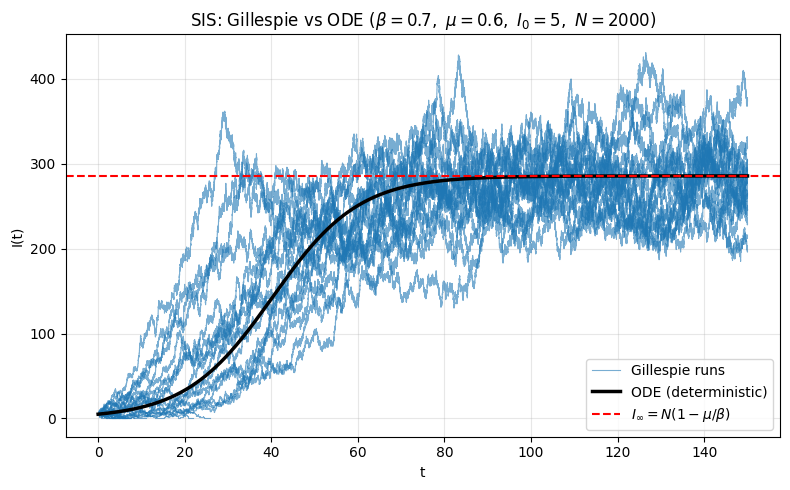

In [ ]:
# EXERCISE 5: Gillespie (stochastic) simulation of the SIS model
# compared with the deterministic ODE solution.

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------------- PARAMETERS ----------------

N, I0, beta, mu = 2000, 5, 0.7, 0.6
# Tmax = how long we simulate
Tmax = 150
# Number of stochastic simulations (runs) to draw on the graph.
n_runs = 30
# Random number generator with a fixed seed, so you get the same graph every time.
rng = np.random.default_rng(42)

# ---------------- THE GILLESPIE ALGORITHM ----------------

# Function that simulates ONE stochastic epidemic and returns its history.
def gillespie(I0, Tmax):
    # Start at time 0.
    t = 0.0
    # Start with I0 infected people.
    I = I0
    # Lists where we record every time and every value of I
    times, infected = [t], [I]
    # Keep going while there are infected people AND we haven't passed Tmax.
    while I > 0 and t < Tmax:
        # Number of susceptible people right now
        S = N - I
        # Rate of a NEW INFECTION
        rate_inf = beta * S * I / N
        # Rate of a RECOVERY
        rate_rec = mu * I
        # Total rate of "something happens".
        rate_tot = rate_inf + rate_rec
        # Time until the next event: random number from an exponential distribution
        # with mean 1/rate_tot.
        t += rng.exponential(1.0 / rate_tot)
        # Decide WHICH event happens: draw a random number between 0 and 1 and
        # compare it with the fraction of the total rate that belongs to infections.
        if rng.random() < rate_inf / rate_tot:
            # The event is an infection: one more infected person.
            I += 1
        else:
            # The event is a recovery: one less infected person.
            I -= 1
        # Save the new time and the new number of infected.
        times.append(t)
        infected.append(I)
    # Give the history back to whoever called the function.
    return np.array(times), np.array(infected)

# ---------------- DETERMINISTIC ODE (for comparison) ----------------

# dI/dt = beta*(N-I)*I/N - mu*I  (the SIS equation with S replaced by N - I).
def ode(t, y):
    # y[0] is I; return its rate of change.
    return [beta * (N - y[0]) * y[0] / N - mu * y[0]]

# Solve the ODE from 0 to Tmax starting at I0; dense_output lets us evaluate it anywhere.
sol = solve_ivp(ode, (0, Tmax), [I0], rtol=1e-9, atol=1e-9, dense_output=True)
# 1000 evenly spaced time points to draw the smooth curve.
t_grid = np.linspace(0, Tmax, 1000)

# ---------------- RUN THE SIMULATIONS AND PLOT ----------------

plt.figure(figsize=(8, 5))
# Counter for how many runs die out (just for information).
extinct = 0
# Repeat the stochastic simulation n_runs times.
for k in range(n_runs):
    # Run one simulation.
    ts, Is = gillespie(I0, Tmax)
    # If the last value of I is 0, the disease disappeared in this run.
    if Is[-1] == 0:
        # Add one to the extinction counter.
        extinct += 1
    # Draw this run as a "steps" line (I only jumps at event times), thin and semi-transparent.
    # The label is written only for the first run so the legend has just one entry.
    plt.step(ts, Is, where="post", lw=0.8, alpha=0.6, color="tab:blue",
             label="Gillespie runs" if k == 0 else None)
# Draw the deterministic ODE solution as a thick black line on top.
plt.plot(t_grid, sol.sol(t_grid)[0], "k-", lw=2.5, label="ODE (deterministic)")
# Draw a dashed red line at the theoretical plateau N*(1 - mu/beta).
plt.axhline(N * (1 - mu / beta), color="r", ls="--", label=r"$I_\infty=N(1-\mu/\beta)$")
# Label the horizontal axis.
plt.xlabel("t")
# Label the vertical axis.
plt.ylabel("I(t)")
# Title of the graph.
plt.title(r"SIS: Gillespie vs ODE ($\beta=0.7,\ \mu=0.6,\ I_0=5,\ N=2000$)")
# Show the legend and a light grid.
plt.legend(); plt.grid(alpha=.3)
# Adjust spacing so nothing is cut off.
plt.tight_layout()
# Save the figure as a PNG file.
plt.savefig("outputs/fig_gillespie_vs_ode.png", dpi=150)

# Print how many of the runs went extinct (disease disappeared).
print(f"{extinct} of {n_runs} runs went extinct")
# Print the ODE plateau and the average I at the end of the runs that survived.
print(f"ODE plateau: {sol.y[0, -1]:.1f}   theory: {N*(1-mu/beta):.1f}")